# Driving Behavior Analysis Model


**Dataset**: Motion sensor data (Accelerometer & Gyroscope)

**Target**: Classify driving behavior into 3 classes - NORMAL, SLOW, AGGRESSIVE


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


1. IMPORT LIBRARIES & LOAD DATA

In [2]:
import pandas as pd
import numpy as np
from scipy import stats
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import ( classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc, mean_squared_error)
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
df = pd.read_csv('/content/train_motion_data (2).csv')

print("DATASET LOADED")
print(f"\nDataset Shape: {df.shape}")
print(f"Number of Records: {df.shape[0]}")
print(f"Number of Features: {df.shape[1]}")
print(f"\nColumn Names:\n{df.columns.tolist()}")
print(f"\nData Types:\n{df.dtypes}")
print(f"\nFirst 5 Rows:\n{df.head()}")

DATASET LOADED

Dataset Shape: (3644, 8)
Number of Records: 3644
Number of Features: 8

Column Names:
['AccX', 'AccY', 'AccZ', 'GyroX', 'GyroY', 'GyroZ', 'Class', 'Timestamp']

Data Types:
AccX         float64
AccY         float64
AccZ         float64
GyroX        float64
GyroY        float64
GyroZ        float64
Class         object
Timestamp      int64
dtype: object

First 5 Rows:
       AccX      AccY      AccZ     GyroX     GyroY     GyroZ   Class  \
0  0.000000  0.000000  0.000000  0.059407 -0.174707  0.101938  NORMAL   
1 -1.624864 -1.082492 -0.204183 -0.028558  0.051313  0.135536  NORMAL   
2 -0.594660 -0.122410  0.220502 -0.019395 -0.029322  0.087888  NORMAL   
3  0.738478 -0.228456  0.667732  0.069791 -0.029932  0.054902  NORMAL   
4  0.101741  0.777568 -0.066730  0.030696 -0.003665  0.054902  NORMAL   

   Timestamp  
0    3581629  
1    3581630  
2    3581630  
3    3581631  
4    3581631  


2. DATA QUALITY & PREPROCESSING

In [ ]:
print("DATA QUALITY CHECK")

print(f"\nMissing Values:\n{df.isnull().sum()}")
print(f"\nTotal Missing Percentage: {(df.isnull().sum().sum() / (df.shape[0]*df.shape[1])) * 100:.2f}%")

print(f"\nDuplicate Rows: {df.duplicated().sum()}")

print(f"\nData Types Info:")
print(df.dtypes)

print(f"\nTarget Variable Distribution (Class):")
print(df['Class'].value_counts())
print(f"\nTarget Distribution Percentage:")
print(df['Class'].value_counts(normalize=True) * 100)

DATA QUALITY CHECK

Missing Values:
AccX         0
AccY         0
AccZ         0
GyroX        0
GyroY        0
GyroZ        0
Class        0
Timestamp    0
dtype: int64

Total Missing Percentage: 0.00%

Duplicate Rows: 0

Data Types Info:
AccX         float64
AccY         float64
AccZ         float64
GyroX        float64
GyroY        float64
GyroZ        float64
Class         object
Timestamp      int64
dtype: object

Target Variable Distribution (Class):
Class
SLOW          1331
NORMAL        1200
AGGRESSIVE    1113
Name: count, dtype: int64

Target Distribution Percentage:
Class
SLOW          36.525796
NORMAL        32.930845
AGGRESSIVE    30.543359
Name: proportion, dtype: float64


In [ ]:
print("STATISTICAL SUMMARY")

print(f"\nBasic Statistics:\n{df.describe().T}")

print(f"\n\nOUTLIER DETECTION (IQR Method):")
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numerical_cols.remove('Timestamp')

outlier_count = {}
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_count[col] = len(outliers)
    print(f"{col}: {len(outliers)} outliers ({(len(outliers)/len(df)*100):.2f}%)")

print(f"\nTotal Outliers Found: {sum(outlier_count.values())}")

STATISTICAL SUMMARY

Basic Statistics:
            count          mean         std           min           25%  \
AccX       3644.0  4.046692e-02    0.985653 -4.636523e+00 -5.506954e-01   
AccY       3644.0 -7.341815e-02    0.903408 -4.699795e+00 -5.925396e-01   
AccZ       3644.0  8.271386e-03    0.985061 -7.143998e+00 -5.584636e-01   
GyroX      3644.0  1.592709e-03    0.066918 -7.518224e-01 -2.855795e-02   
GyroY      3644.0 -1.273027e-03    0.126205 -1.587028e+00 -5.375614e-02   
GyroZ      3644.0  7.949043e-03    0.115687 -1.236468e+00 -2.939789e-02   
Timestamp  3644.0  3.582707e+06  642.147947  3.581629e+06  3.582121e+06   

                    50%           75%           max  
AccX       3.931045e-03  5.959871e-01  4.985548e+00  
AccY      -8.083267e-02  4.524008e-01  4.245151e+00  
AccZ       2.261639e-03  5.561569e-01  5.171739e+00  
GyroX      1.985312e-03  3.191771e-02  8.492554e-01  
GyroY     -1.832596e-03  5.131268e-02  1.679879e+00  
GyroZ      2.977968e-03  4.085161e-0

3. EXPLORATORY DATA ANALYSIS (EDA)

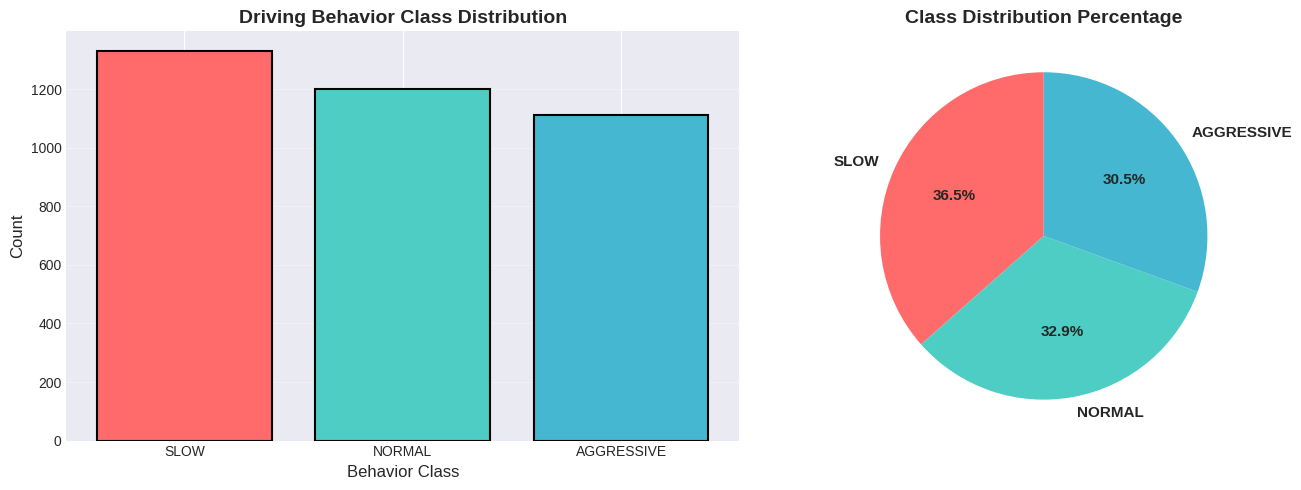

✓ Class distribution looks balanced (no severe class imbalance)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

class_counts = df['Class'].value_counts()
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
axes[0].bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', linewidth=1.5)
axes[0].set_title('Driving Behavior Class Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Behavior Class', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].grid(axis='y', alpha=0.3)

axes[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[1].set_title('Class Distribution Percentage', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("✓ Class distribution looks balanced (no severe class imbalance)")

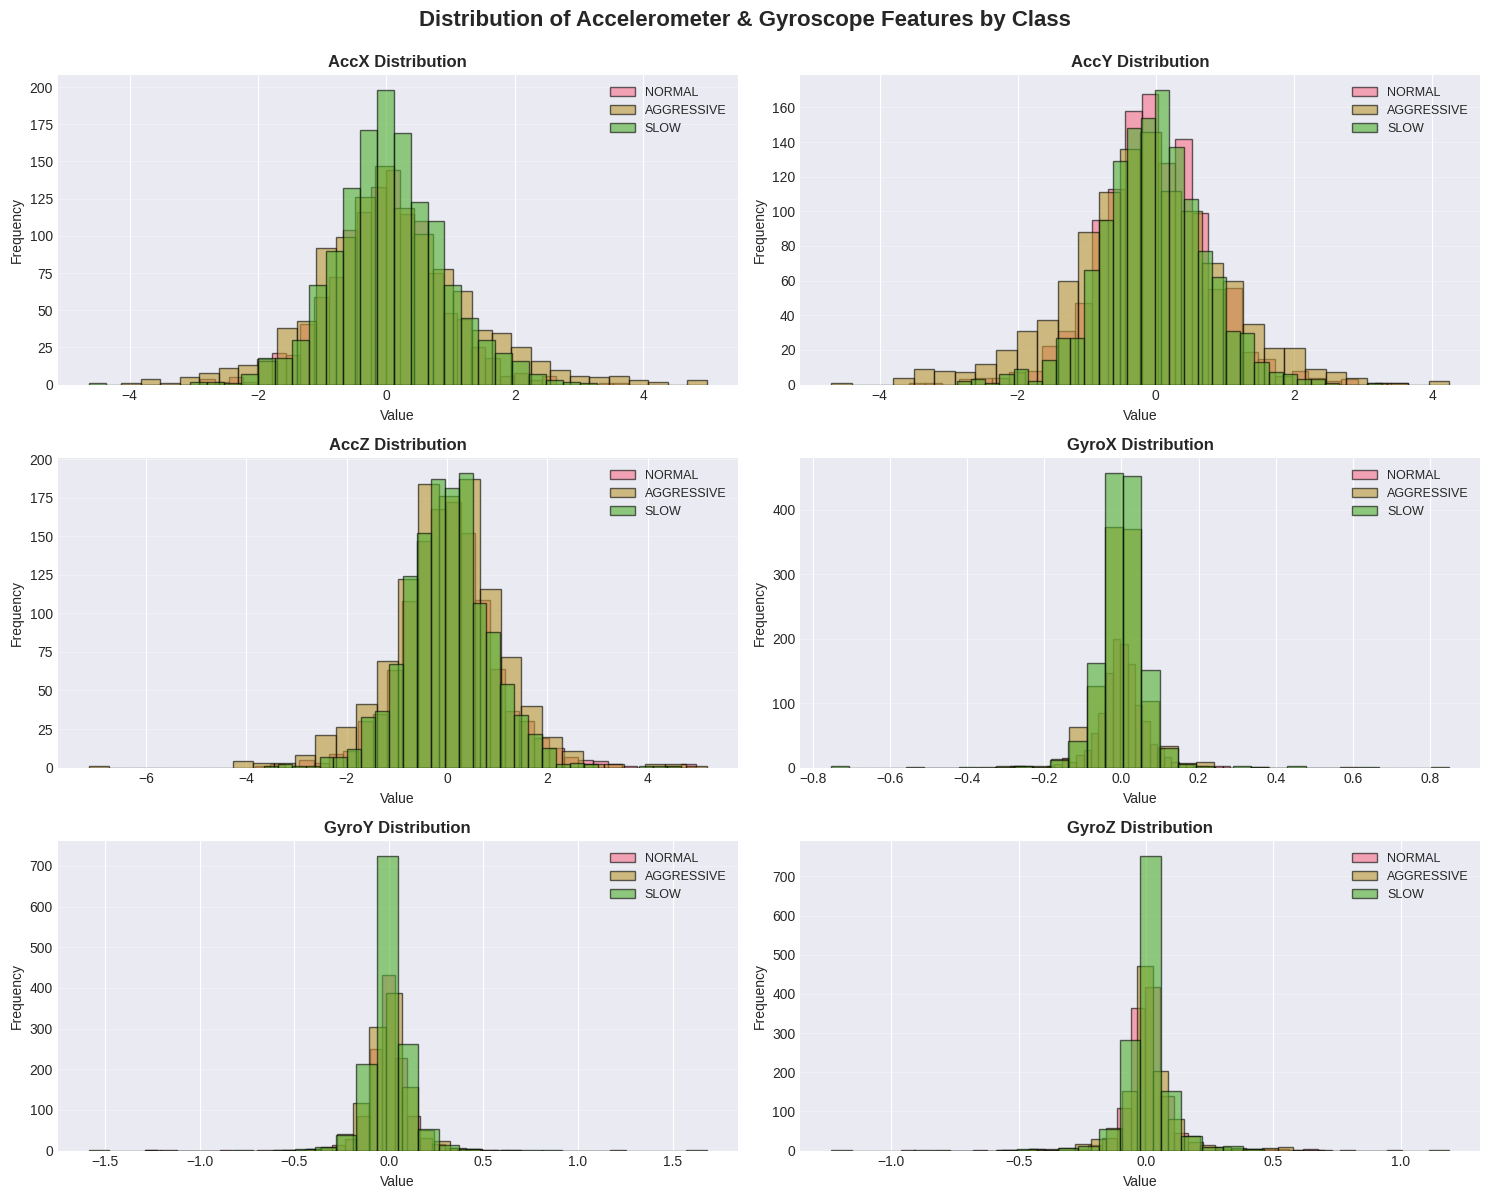

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle('Distribution of Accelerometer & Gyroscope Features by Class',
             fontsize=16, fontweight='bold', y=0.995)

feature_list = ['AccX', 'AccY', 'AccZ', 'GyroX', 'GyroY', 'GyroZ']
classes = df['Class'].unique()

for idx, feature in enumerate(feature_list):
    ax = axes[idx // 2, idx % 2]

    for class_label in classes:
        data = df[df['Class'] == class_label][feature]
        ax.hist(data, alpha=0.6, label=class_label, bins=30, edgecolor='black')

    ax.set_title(f'{feature} Distribution', fontsize=12, fontweight='bold')
    ax.set_xlabel('Value', fontsize=10)
    ax.set_ylabel('Frequency', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

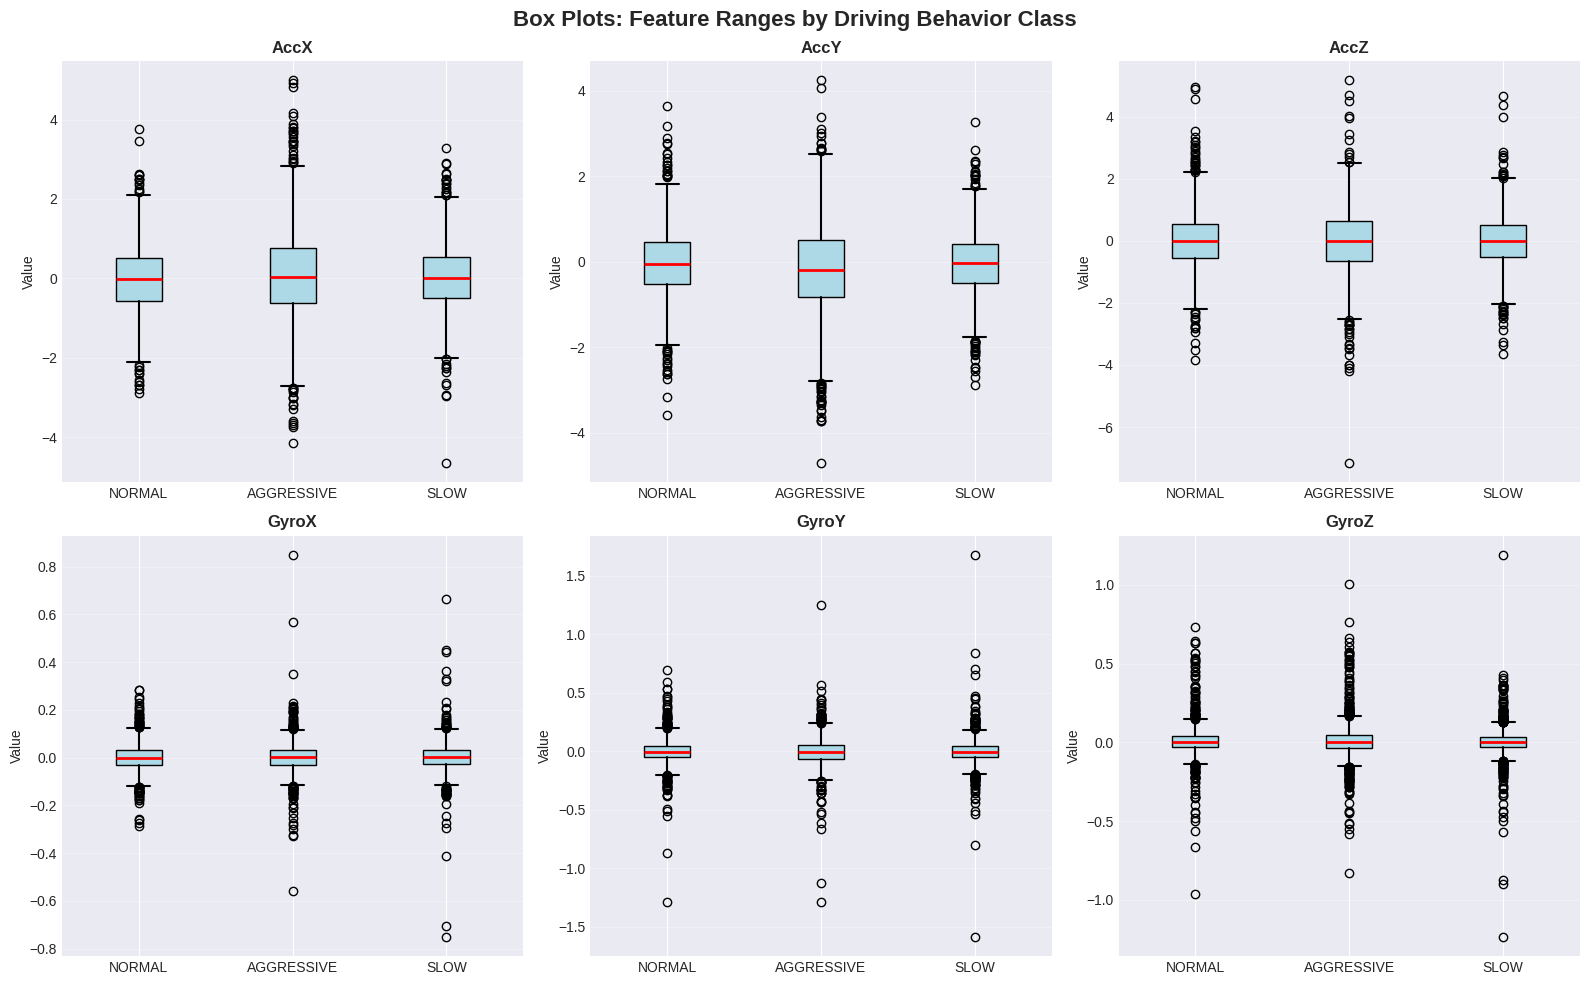

✓ Box plots show clear separation between classes for some features


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Box Plots: Feature Ranges by Driving Behavior Class',
             fontsize=16, fontweight='bold')

for idx, feature in enumerate(feature_list):
    ax = axes[idx // 3, idx % 3]

    data_to_plot = [df[df['Class'] == c][feature].values for c in classes]
    bp = ax.boxplot(data_to_plot, labels=classes, patch_artist=True,
                     medianprops=dict(color='red', linewidth=2),
                     boxprops=dict(facecolor='lightblue', edgecolor='black'),
                     whiskerprops=dict(color='black', linewidth=1.5),
                     capprops=dict(color='black', linewidth=1.5))

    ax.set_title(f'{feature}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Value', fontsize=10)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("✓ Box plots show clear separation between classes for some features")

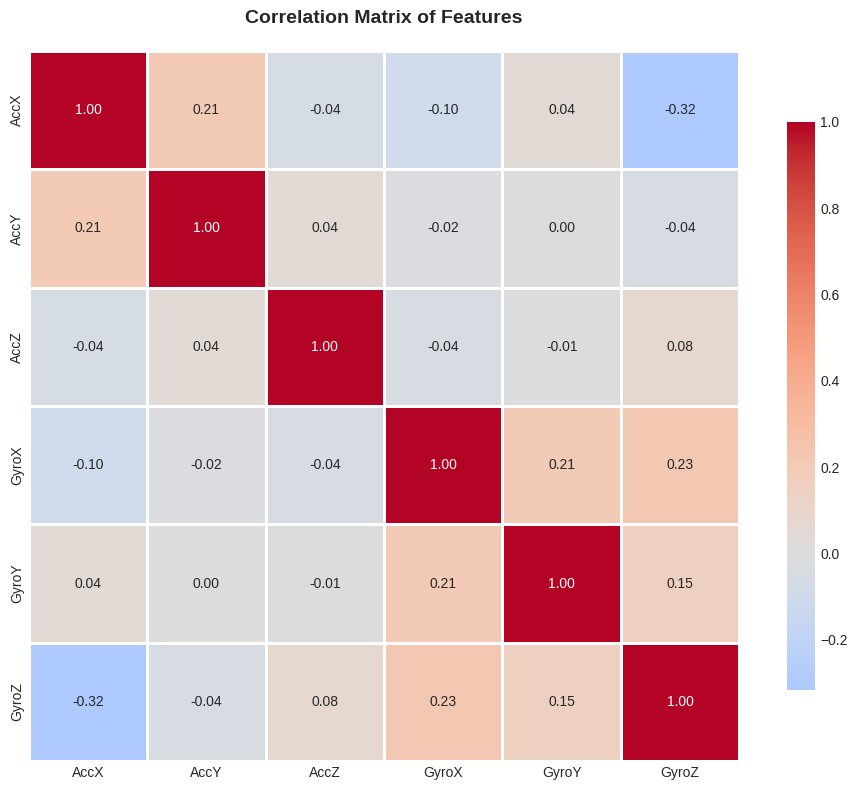


Key Correlations:
1. AccX <-> GyroZ: -0.3162
2. GyroX <-> GyroZ: 0.2286
3. GyroX <-> GyroY: 0.2097
4. AccX <-> AccY: 0.2076
5. GyroY <-> GyroZ: 0.1541


In [ ]:
correlation_matrix = df[feature_list].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8},
            ax=ax)
ax.set_title('Correlation Matrix of Features', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\nKey Correlations:")
corr_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        corr_pairs.append((
            correlation_matrix.columns[i],
            correlation_matrix.columns[j],
            correlation_matrix.iloc[i, j]
        ))

corr_pairs.sort(key=lambda x: abs(x[2]), reverse=True)
for i, (feat1, feat2, corr) in enumerate(corr_pairs[:5]):
    print(f"{i+1}. {feat1} <-> {feat2}: {corr:.4f}")

In [ ]:
print("FEATURE STATISTICS BY CLASS")


for feature in feature_list:
    print(f"\n{feature}:")
    for class_label in sorted(df['Class'].unique()):
        data = df[df['Class'] == class_label][feature]
        print(f"  {class_label:12s} - Mean: {data.mean():8.4f}, Std: {data.std():8.4f}, "
              f"Min: {data.min():8.4f}, Max: {data.max():8.4f}")

FEATURE STATISTICS BY CLASS

AccX:
  AGGRESSIVE   - Mean:   0.0961, Std:   1.2183, Min:  -4.1329, Max:   4.9855
  NORMAL       - Mean:  -0.0180, Std:   0.8662, Min:  -2.8973, Max:   3.7570
  SLOW         - Mean:   0.0466, Std:   0.8590, Min:  -4.6365, Max:   3.2782

AccY:
  AGGRESSIVE   - Mean:  -0.1705, Std:   1.1387, Min:  -4.6998, Max:   4.2452
  NORMAL       - Mean:  -0.0277, Std:   0.8144, Min:  -3.5788, Max:   3.6508
  SLOW         - Mean:  -0.0335, Std:   0.7364, Min:  -2.8811, Max:   3.2739

AccZ:
  AGGRESSIVE   - Mean:  -0.0211, Std:   1.1292, Min:  -7.1440, Max:   5.1717
  NORMAL       - Mean:   0.0344, Std:   0.9645, Min:  -3.8255, Max:   4.9543
  SLOW         - Mean:   0.0093, Std:   0.8671, Min:  -3.6526, Max:   4.6649

GyroX:
  AGGRESSIVE   - Mean:   0.0002, Std:   0.0717, Min:  -0.5582, Max:   0.8493
  NORMAL       - Mean:   0.0019, Std:   0.0607, Min:  -0.2876, Max:   0.2818
  SLOW         - Mean:   0.0025, Std:   0.0681, Min:  -0.7518, Max:   0.6666

GyroY:
  AGGRESSIV

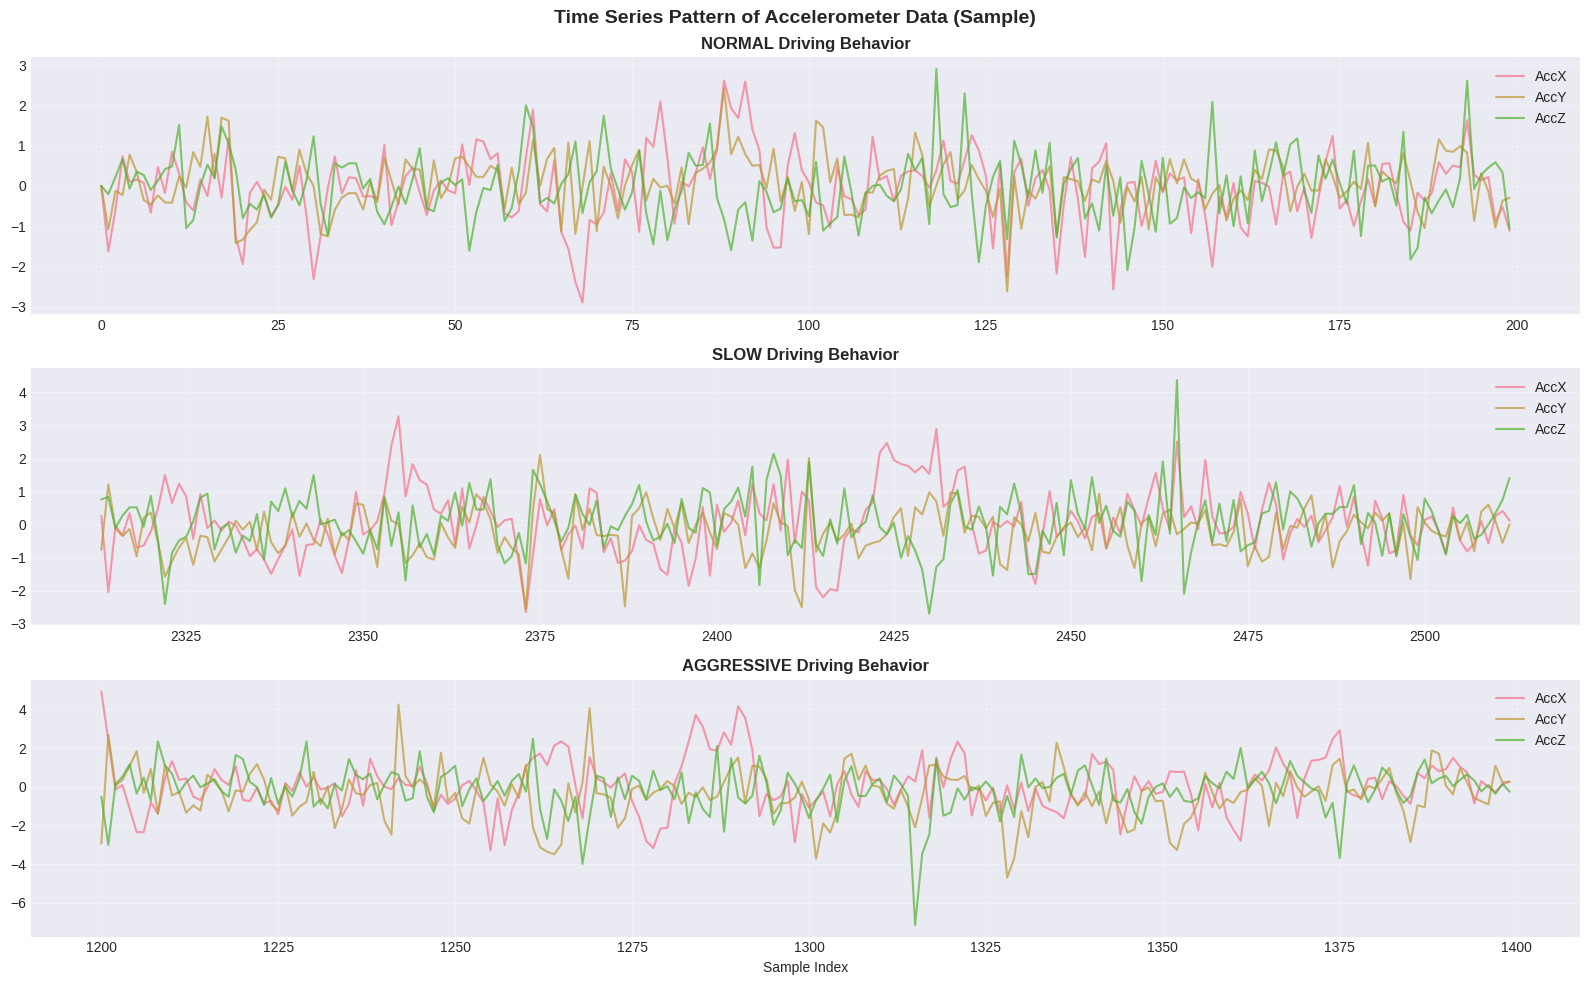

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(16, 10))
fig.suptitle('Time Series Pattern of Accelerometer Data (Sample)',
             fontsize=14, fontweight='bold')

sample_normal = df[df['Class'] == 'NORMAL'].head(200)
sample_slow = df[df['Class'] == 'SLOW'].head(200)
sample_aggressive = df[df['Class'] == 'AGGRESSIVE'].head(200)

axes[0].plot(sample_normal.index, sample_normal['AccX'], label='AccX', linewidth=1.5, alpha=0.7)
axes[0].plot(sample_normal.index, sample_normal['AccY'], label='AccY', linewidth=1.5, alpha=0.7)
axes[0].plot(sample_normal.index, sample_normal['AccZ'], label='AccZ', linewidth=1.5, alpha=0.7)
axes[0].set_title('NORMAL Driving Behavior', fontweight='bold')
axes[0].legend(loc='upper right')
axes[0].grid(alpha=0.3)

axes[1].plot(sample_slow.index, sample_slow['AccX'], label='AccX', linewidth=1.5, alpha=0.7)
axes[1].plot(sample_slow.index, sample_slow['AccY'], label='AccY', linewidth=1.5, alpha=0.7)
axes[1].plot(sample_slow.index, sample_slow['AccZ'], label='AccZ', linewidth=1.5, alpha=0.7)
axes[1].set_title('SLOW Driving Behavior', fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].grid(alpha=0.3)

axes[2].plot(sample_aggressive.index, sample_aggressive['AccX'], label='AccX', linewidth=1.5, alpha=0.7)
axes[2].plot(sample_aggressive.index, sample_aggressive['AccY'], label='AccY', linewidth=1.5, alpha=0.7)
axes[2].plot(sample_aggressive.index, sample_aggressive['AccZ'], label='AccZ', linewidth=1.5, alpha=0.7)
axes[2].set_title('AGGRESSIVE Driving Behavior', fontweight='bold')
axes[2].set_xlabel('Sample Index')
axes[2].legend(loc='upper right')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

4. FEATURE ENGINEERING & JERK ANALYSIS


In [ ]:
df_features = df.copy()

print("FEATURE ENGINEERING")


print("\n1. JERK CALCULATION (Sequential Differences)")


df_features['JerkX'] = df_features['AccX'].diff().fillna(0)
df_features['JerkY'] = df_features['AccY'].diff().fillna(0)
df_features['JerkZ'] = df_features['AccZ'].diff().fillna(0)

print(f"Created JerkX, JerkY, JerkZ features")
print(f"Jerk Statistics (sample):")
print(df_features[['JerkX', 'JerkY', 'JerkZ']].describe())

FEATURE ENGINEERING

1. JERK CALCULATION (Sequential Differences)
Created JerkX, JerkY, JerkZ features
Jerk Statistics (sample):
             JerkX        JerkY        JerkZ
count  3644.000000  3644.000000  3644.000000
mean     -0.000110     0.000111    -0.000116
std       1.072145     1.069747     1.376495
min      -5.706999    -4.541037    -6.669646
25%      -0.665266    -0.658628    -0.785964
50%       0.022132    -0.012872     0.006853
75%       0.676928     0.659883     0.801030
max       4.369801     6.718676     6.639951


In [ ]:
print("\n2. MAGNITUDE-BASED FEATURES\n\n")



df_features['AccMagnitude'] = np.sqrt(df_features['AccX']**2 +
                                        df_features['AccY']**2 +
                                        df_features['AccZ']**2)

df_features['GyroMagnitude'] = np.sqrt(df_features['GyroX']**2 +
                                         df_features['GyroY']**2 +
                                         df_features['GyroZ']**2)

df_features['JerkMagnitude'] = np.sqrt(df_features['JerkX']**2 +
                                         df_features['JerkY']**2 +
                                         df_features['JerkZ']**2)

print(f"Created AccMagnitude, GyroMagnitude, JerkMagnitude features")
print(f"Magnitude Statistics:")
print(df_features[['AccMagnitude', 'GyroMagnitude', 'JerkMagnitude']].describe())


2. MAGNITUDE-BASED FEATURES


Created AccMagnitude, GyroMagnitude, JerkMagnitude features
Magnitude Statistics:
       AccMagnitude  GyroMagnitude  JerkMagnitude
count   3644.000000    3644.000000    3644.000000
mean       1.437810       0.130792       1.788648
std        0.835007       0.129403       0.994209
min        0.000000       0.003707       0.000000
25%        0.852041       0.058421       1.090478
50%        1.268063       0.096627       1.586346
75%        1.843263       0.157922       2.258135
max        7.451246       1.957027       7.146545


In [ ]:
print("\n3. ROLLING WINDOW STATISTICS\n\n")


window_size = 30

df_features['AccX_rolling_mean'] = df_features['AccX'].rolling(window=window_size, min_periods=1).mean()
df_features['AccY_rolling_mean'] = df_features['AccY'].rolling(window=window_size, min_periods=1).mean()
df_features['AccZ_rolling_mean'] = df_features['AccZ'].rolling(window=window_size, min_periods=1).mean()

df_features['AccX_rolling_std'] = df_features['AccX'].rolling(window=window_size, min_periods=1).std().fillna(0)
df_features['AccY_rolling_std'] = df_features['AccY'].rolling(window=window_size, min_periods=1).std().fillna(0)
df_features['AccZ_rolling_std'] = df_features['AccZ'].rolling(window=window_size, min_periods=1).std().fillna(0)

df_features['JerkX_rolling_mean'] = df_features['JerkX'].rolling(window=window_size, min_periods=1).mean()
df_features['JerkY_rolling_mean'] = df_features['JerkY'].rolling(window=window_size, min_periods=1).mean()
df_features['JerkZ_rolling_mean'] = df_features['JerkZ'].rolling(window=window_size, min_periods=1).mean()


df_features['JerkX_rolling_max'] = df_features['JerkX'].rolling(window=window_size, min_periods=1).max()
df_features['JerkY_rolling_max'] = df_features['JerkY'].rolling(window=window_size, min_periods=1).max()
df_features['JerkZ_rolling_max'] = df_features['JerkZ'].rolling(window=window_size, min_periods=1).max()

print(f"Created rolling mean and std for accelerations and jerk")
print(f"Total features created in rolling window: 12")


3. ROLLING WINDOW STATISTICS


Created rolling mean and std for accelerations and jerk
Total features created in rolling window: 12


In [ ]:
print("\n4. STATISTICAL AGGREGATION FEATURES\n\n")

df_features['AccX_var'] = df_features['AccX'] ** 2
df_features['AccY_var'] = df_features['AccY'] ** 2
df_features['AccZ_var'] = df_features['AccZ'] ** 2

df_features['JerkX_var'] = df_features['JerkX'] ** 2
df_features['JerkY_var'] = df_features['JerkY'] ** 2
df_features['JerkZ_var'] = df_features['JerkZ'] ** 2

df_features['AbsAccX'] = abs(df_features['AccX'])
df_features['AbsAccY'] = abs(df_features['AccY'])
df_features['AbsAccZ'] = abs(df_features['AccZ'])
df_features['AbsJerkX'] = abs(df_features['JerkX'])
df_features['AbsJerkY'] = abs(df_features['JerkY'])
df_features['AbsJerkZ'] = abs(df_features['JerkZ'])

df_features['Acc_Energy'] = (df_features['AccX']**2 + df_features['AccY']**2 + df_features['AccZ']**2) / 3
df_features['Jerk_Energy'] = (df_features['JerkX']**2 + df_features['JerkY']**2 + df_features['JerkZ']**2) / 3

print(f"Created variance, absolute, and energy features")
print(f"Total new features: 18")


4. STATISTICAL AGGREGATION FEATURES


Created variance, absolute, and energy features
Total new features: 18


In [ ]:
print("FEATURE ENGINEERING SUMMARY\n \n")

original_features = ['AccX', 'AccY', 'AccZ', 'GyroX', 'GyroY', 'GyroZ']
engineered_features = [col for col in df_features.columns if col not in original_features + ['Class', 'Timestamp']]

print(f"\nOriginal Features: {len(original_features)}")
print(f"  {original_features}")
print(f"\nEngineered Features: {len(engineered_features)}")

jerk_features = [f for f in engineered_features if 'Jerk' in f]
magnitude_features = [f for f in engineered_features if 'Magnitude' in f]
rolling_features = [f for f in engineered_features if 'rolling' in f]
other_features = [f for f in engineered_features if f not in jerk_features + magnitude_features + rolling_features]

print(f"\n  Jerk Features ({len(jerk_features)}): {jerk_features}")
print(f"  Magnitude Features ({len(magnitude_features)}): {magnitude_features}")
print(f"  Rolling Window Features ({len(rolling_features)}): {rolling_features}")
print(f"  Other Features ({len(other_features)}): {other_features}")

print(f"\nTOTAL FEATURES FOR MODELING: {len(original_features) + len(engineered_features)}")
print(f"\nDataset shape after feature engineering: {df_features.shape}")

FEATURE ENGINEERING SUMMARY
 


Original Features: 6
  ['AccX', 'AccY', 'AccZ', 'GyroX', 'GyroY', 'GyroZ']

Engineered Features: 32

  Jerk Features (17): ['JerkX', 'JerkY', 'JerkZ', 'JerkMagnitude', 'JerkX_rolling_mean', 'JerkY_rolling_mean', 'JerkZ_rolling_mean', 'JerkX_rolling_max', 'JerkY_rolling_max', 'JerkZ_rolling_max', 'JerkX_var', 'JerkY_var', 'JerkZ_var', 'AbsJerkX', 'AbsJerkY', 'AbsJerkZ', 'Jerk_Energy']
  Magnitude Features (3): ['AccMagnitude', 'GyroMagnitude', 'JerkMagnitude']
  Rolling Window Features (12): ['AccX_rolling_mean', 'AccY_rolling_mean', 'AccZ_rolling_mean', 'AccX_rolling_std', 'AccY_rolling_std', 'AccZ_rolling_std', 'JerkX_rolling_mean', 'JerkY_rolling_mean', 'JerkZ_rolling_mean', 'JerkX_rolling_max', 'JerkY_rolling_max', 'JerkZ_rolling_max']
  Other Features (7): ['AccX_var', 'AccY_var', 'AccZ_var', 'AbsAccX', 'AbsAccY', 'AbsAccZ', 'Acc_Energy']

TOTAL FEATURES FOR MODELING: 38

Dataset shape after feature engineering: (3644, 40)


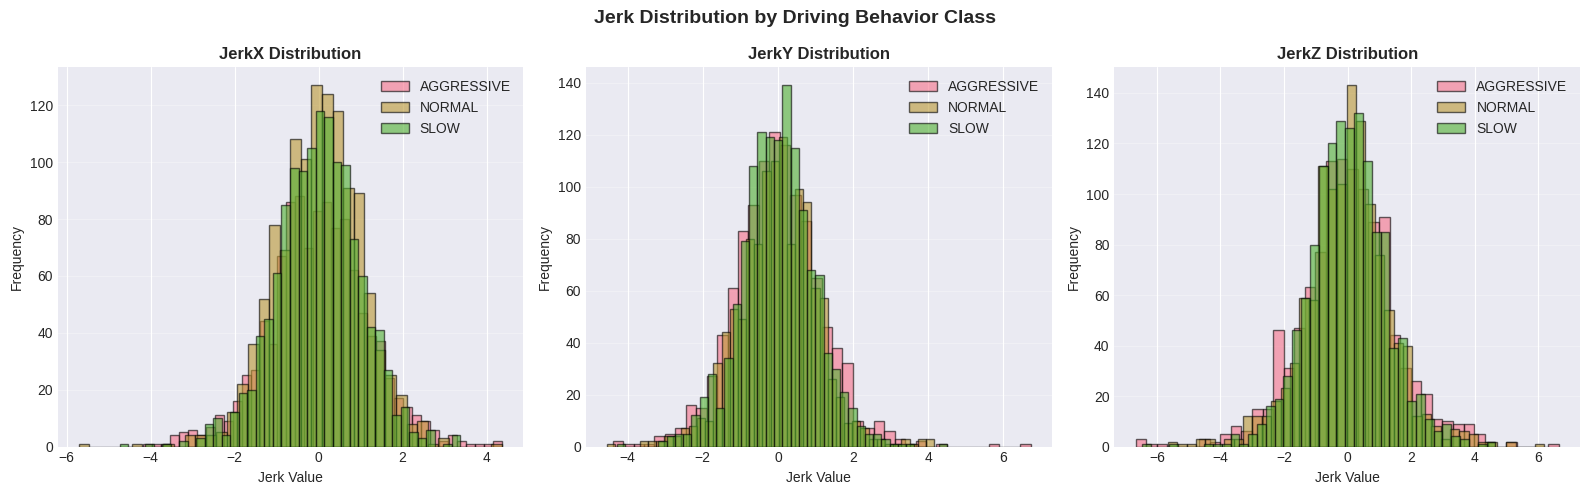

✓ Jerk features show distinct patterns across classes!


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Jerk Distribution by Driving Behavior Class', fontsize=14, fontweight='bold')

jerk_cols = ['JerkX', 'JerkY', 'JerkZ']
for idx, col in enumerate(jerk_cols):
    for class_label in sorted(df_features['Class'].unique()):
        data = df_features[df_features['Class'] == class_label][col]
        axes[idx].hist(data, alpha=0.6, label=class_label, bins=40, edgecolor='black')

    axes[idx].set_title(f'{col} Distribution', fontweight='bold')
    axes[idx].set_xlabel('Jerk Value')
    axes[idx].set_ylabel('Frequency')
    axes[idx].legend()
    axes[idx].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("✓ Jerk features show distinct patterns across classes!")

5. DATA PREPARATION FOR MODELING

In [ ]:
print("DATA PREPARATION FOR MODELING\n \n")


feature_cols = [col for col in df_features.columns if col not in ['Class', 'Timestamp']]

X = df_features[feature_cols].copy()
y = df_features['Class'].copy()

print(f"\nFeature Matrix Shape: {X.shape}")
print(f"Target Variable Shape: {y.shape}")
print(f"\nNumber of Features: {X.shape[1]}")
print(f"Feature Names:\n{X.columns.tolist()}")

print(f"\nMissing Values in Features:")
missing = X.isnull().sum()
if missing.sum() > 0:
    print(missing[missing > 0])
    X = X.fillna(0)
    print("✓ Missing values filled with 0")
else:
    print("✓ No missing values!")

DATA PREPARATION FOR MODELING
 


Feature Matrix Shape: (3644, 38)
Target Variable Shape: (3644,)

Number of Features: 38
Feature Names:
['AccX', 'AccY', 'AccZ', 'GyroX', 'GyroY', 'GyroZ', 'JerkX', 'JerkY', 'JerkZ', 'AccMagnitude', 'GyroMagnitude', 'JerkMagnitude', 'AccX_rolling_mean', 'AccY_rolling_mean', 'AccZ_rolling_mean', 'AccX_rolling_std', 'AccY_rolling_std', 'AccZ_rolling_std', 'JerkX_rolling_mean', 'JerkY_rolling_mean', 'JerkZ_rolling_mean', 'JerkX_rolling_max', 'JerkY_rolling_max', 'JerkZ_rolling_max', 'AccX_var', 'AccY_var', 'AccZ_var', 'JerkX_var', 'JerkY_var', 'JerkZ_var', 'AbsAccX', 'AbsAccY', 'AbsAccZ', 'AbsJerkX', 'AbsJerkY', 'AbsJerkZ', 'Acc_Energy', 'Jerk_Energy']

Missing Values in Features:
✓ No missing values!


In [ ]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("\nTarget Variable Encoding:\n")
for idx, class_label in enumerate(label_encoder.classes_):
    print(f"  {class_label} → {idx}")

print(f"\nEncoded Target Distribution:\n")
unique, counts = np.unique(y_encoded, return_counts=True)
for u, c in zip(unique, counts):
    class_name = label_encoder.inverse_transform([u])[0]
    print(f"  {class_name}: {c} samples ({c/len(y_encoded)*100:.2f}%)")


Target Variable Encoding:

  AGGRESSIVE → 0
  NORMAL → 1
  SLOW → 2

Encoded Target Distribution:

  AGGRESSIVE: 1113 samples (30.54%)
  NORMAL: 1200 samples (32.93%)
  SLOW: 1331 samples (36.53%)


In [ ]:
print("\nTrain-Test Split (80-20):")
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Training Set Size: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.2f}%)")
print(f"Test Set Size: {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.2f}%)")
print(f"\nTraining Set Class Distribution:")
for u, c in zip(*np.unique(y_train, return_counts=True)):
    class_name = label_encoder.inverse_transform([u])[0]
    print(f"  {class_name}: {c} samples")
print(f"\nTest Set Class Distribution:")
for u, c in zip(*np.unique(y_test, return_counts=True)):
    class_name = label_encoder.inverse_transform([u])[0]
    print(f"  {class_name}: {c} samples")


Train-Test Split (80-20):
Training Set Size: 2915 samples (79.99%)
Test Set Size: 729 samples (20.01%)

Training Set Class Distribution:
  AGGRESSIVE: 890 samples
  NORMAL: 960 samples
  SLOW: 1065 samples

Test Set Class Distribution:
  AGGRESSIVE: 223 samples
  NORMAL: 240 samples
  SLOW: 266 samples


In [ ]:
print("\nFeature Scaling:")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✓ Features scaled using StandardScaler")
print(f"\nScaled Training Data Statistics:")
print(f"  Mean: {X_train_scaled.mean():.6f}")
print(f"  Std Dev: {X_train_scaled.std():.6f}")
print(f"  Min: {X_train_scaled.min():.6f}")
print(f"  Max: {X_train_scaled.max():.6f}")


Feature Scaling:
✓ Features scaled using StandardScaler

Scaled Training Data Statistics:
  Mean: -0.000000
  Std Dev: 1.000000
  Min: -16.793035
  Max: 23.610539


## 6. MODEL TRAINING & EVALUATION

In [ ]:
models_dict = {}
results_dict = {}

print("TRAINING MULTIPLE SCIKIT-LEARN MODELS")

print("\n1. LOGISTIC REGRESSION\n")

lr_model = LogisticRegression(max_iter=1000, random_state=42, multi_class='multinomial')
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_proba_lr = lr_model.predict_proba(X_test_scaled)

models_dict['Logistic Regression'] = lr_model
results_dict['Logistic Regression'] = {
    'predictions': y_pred_lr,
    'probabilities': y_pred_proba_lr,
    'accuracy': accuracy_score(y_test, y_pred_lr),
    'precision': precision_score(y_test, y_pred_lr, average='weighted'),
    'recall': recall_score(y_test, y_pred_lr, average='weighted'),
    'f1': f1_score(y_test, y_pred_lr, average='weighted')
}

print(f"Accuracy: {results_dict['Logistic Regression']['accuracy']:.4f}")
print(f"Precision (Weighted): {results_dict['Logistic Regression']['precision']:.4f}")
print(f"Recall (Weighted): {results_dict['Logistic Regression']['recall']:.4f}")
print(f"F1-Score (Weighted): {results_dict['Logistic Regression']['f1']:.4f}")

TRAINING MULTIPLE SCIKIT-LEARN MODELS

1. LOGISTIC REGRESSION

Accuracy: 0.5926
Precision (Weighted): 0.5940
Recall (Weighted): 0.5926
F1-Score (Weighted): 0.5893


In [ ]:
print("\n2. RANDOM FOREST CLASSIFIER\n \n")

rf_model = RandomForestClassifier(n_estimators=100, max_depth=20,
                                   random_state=42, n_jobs=-1, min_samples_split=5)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_proba_rf = rf_model.predict_proba(X_test_scaled)

models_dict['Random Forest'] = rf_model
results_dict['Random Forest'] = {
    'predictions': y_pred_rf,
    'probabilities': y_pred_proba_rf,
    'accuracy': accuracy_score(y_test, y_pred_rf),
    'precision': precision_score(y_test, y_pred_rf, average='weighted'),
    'recall': recall_score(y_test, y_pred_rf, average='weighted'),
    'f1': f1_score(y_test, y_pred_rf, average='weighted')
}

print(f"Accuracy: {results_dict['Random Forest']['accuracy']:.4f}")
print(f"Precision (Weighted): {results_dict['Random Forest']['precision']:.4f}")
print(f"Recall (Weighted): {results_dict['Random Forest']['recall']:.4f}")
print(f"F1-Score (Weighted): {results_dict['Random Forest']['f1']:.4f}")

feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\nTop 10 Most Important Features:")
print(feature_importance.head(10).to_string(index=False))


2. RANDOM FOREST CLASSIFIER
 

Accuracy: 0.9588
Precision (Weighted): 0.9594
Recall (Weighted): 0.9588
F1-Score (Weighted): 0.9589

Top 10 Most Important Features:
          feature  importance
 AccY_rolling_std    0.155708
 AccX_rolling_std    0.102984
JerkX_rolling_max    0.095911
JerkY_rolling_max    0.081600
JerkZ_rolling_max    0.077124
 AccZ_rolling_std    0.062322
AccY_rolling_mean    0.058832
AccZ_rolling_mean    0.049814
AccX_rolling_mean    0.043193
            GyroZ    0.018691


In [ ]:
print("\n3. GRADIENT BOOSTING CLASSIFIER\n \n")

gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                       max_depth=7, random_state=42)
gb_model.fit(X_train_scaled, y_train)
y_pred_gb = gb_model.predict(X_test_scaled)
y_pred_proba_gb = gb_model.predict_proba(X_test_scaled)

models_dict['Gradient Boosting'] = gb_model
results_dict['Gradient Boosting'] = {
    'predictions': y_pred_gb,
    'probabilities': y_pred_proba_gb,
    'accuracy': accuracy_score(y_test, y_pred_gb),
    'precision': precision_score(y_test, y_pred_gb, average='weighted'),
    'recall': recall_score(y_test, y_pred_gb, average='weighted'),
    'f1': f1_score(y_test, y_pred_gb, average='weighted')
}

print(f"Accuracy: {results_dict['Gradient Boosting']['accuracy']:.4f}")
print(f"Precision (Weighted): {results_dict['Gradient Boosting']['precision']:.4f}")
print(f"Recall (Weighted): {results_dict['Gradient Boosting']['recall']:.4f}")
print(f"F1-Score (Weighted): {results_dict['Gradient Boosting']['f1']:.4f}")


3. GRADIENT BOOSTING CLASSIFIER
 

Accuracy: 0.9918
Precision (Weighted): 0.9918
Recall (Weighted): 0.9918
F1-Score (Weighted): 0.9917


In [ ]:
print("\n4. SUPPORT VECTOR MACHINE (SVM)\n \n")

svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)
y_pred_proba_svm = svm_model.predict_proba(X_test_scaled)

models_dict['SVM'] = svm_model
results_dict['SVM'] = {
    'predictions': y_pred_svm,
    'probabilities': y_pred_proba_svm,
    'accuracy': accuracy_score(y_test, y_pred_svm),
    'precision': precision_score(y_test, y_pred_svm, average='weighted'),
    'recall': recall_score(y_test, y_pred_svm, average='weighted'),
    'f1': f1_score(y_test, y_pred_svm, average='weighted')
}

print(f"Accuracy: {results_dict['SVM']['accuracy']:.4f}")
print(f"Precision (Weighted): {results_dict['SVM']['precision']:.4f}")
print(f"Recall (Weighted): {results_dict['SVM']['recall']:.4f}")
print(f"F1-Score (Weighted): {results_dict['SVM']['f1']:.4f}")


4. SUPPORT VECTOR MACHINE (SVM)
 

Accuracy: 0.6255
Precision (Weighted): 0.6245
Recall (Weighted): 0.6255
F1-Score (Weighted): 0.6233


In [ ]:
print("\n5. K-NEAREST NEIGHBORS (KNN)\n\n")

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)
y_pred_proba_knn = knn_model.predict_proba(X_test_scaled)

models_dict['KNN'] = knn_model
results_dict['KNN'] = {
    'predictions': y_pred_knn,
    'probabilities': y_pred_proba_knn,
    'accuracy': accuracy_score(y_test, y_pred_knn),
    'precision': precision_score(y_test, y_pred_knn, average='weighted'),
    'recall': recall_score(y_test, y_pred_knn, average='weighted'),
    'f1': f1_score(y_test, y_pred_knn, average='weighted')
}

print(f"Accuracy: {results_dict['KNN']['accuracy']:.4f}")
print(f"Precision (Weighted): {results_dict['KNN']['precision']:.4f}")
print(f"Recall (Weighted): {results_dict['KNN']['recall']:.4f}")
print(f"F1-Score (Weighted): {results_dict['KNN']['f1']:.4f}")


5. K-NEAREST NEIGHBORS (KNN)


Accuracy: 0.6036
Precision (Weighted): 0.6161
Recall (Weighted): 0.6036
F1-Score (Weighted): 0.6077


In [ ]:
print("\n6. DECISION TREE CLASSIFIER\n \n")

dt_model = DecisionTreeClassifier(max_depth=15, random_state=42, min_samples_split=5)
dt_model.fit(X_train_scaled, y_train)
y_pred_dt = dt_model.predict(X_test_scaled)
y_pred_proba_dt = dt_model.predict_proba(X_test_scaled)

models_dict['Decision Tree'] = dt_model
results_dict['Decision Tree'] = {
    'predictions': y_pred_dt,
    'probabilities': y_pred_proba_dt,
    'accuracy': accuracy_score(y_test, y_pred_dt),
    'precision': precision_score(y_test, y_pred_dt, average='weighted'),
    'recall': recall_score(y_test, y_pred_dt, average='weighted'),
    'f1': f1_score(y_test, y_pred_dt, average='weighted')
}

print(f"Accuracy: {results_dict['Decision Tree']['accuracy']:.4f}")
print(f"Precision (Weighted): {results_dict['Decision Tree']['precision']:.4f}")
print(f"Recall (Weighted): {results_dict['Decision Tree']['recall']:.4f}")
print(f"F1-Score (Weighted): {results_dict['Decision Tree']['f1']:.4f}")


6. DECISION TREE CLASSIFIER
 

Accuracy: 0.8944
Precision (Weighted): 0.8958
Recall (Weighted): 0.8944
F1-Score (Weighted): 0.8944


In [ ]:
print("\n7. GAUSSIAN NAIVE BAYES\n \n")

nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)
y_pred_nb = nb_model.predict(X_test_scaled)
y_pred_proba_nb = nb_model.predict_proba(X_test_scaled)

models_dict['Naive Bayes'] = nb_model
results_dict['Naive Bayes'] = {
    'predictions': y_pred_nb,
    'probabilities': y_pred_proba_nb,
    'accuracy': accuracy_score(y_test, y_pred_nb),
    'precision': precision_score(y_test, y_pred_nb, average='weighted'),
    'recall': recall_score(y_test, y_pred_nb, average='weighted'),
    'f1': f1_score(y_test, y_pred_nb, average='weighted')
}

print(f"Accuracy: {results_dict['Naive Bayes']['accuracy']:.4f}")
print(f"Precision (Weighted): {results_dict['Naive Bayes']['precision']:.4f}")
print(f"Recall (Weighted): {results_dict['Naive Bayes']['recall']:.4f}")
print(f"F1-Score (Weighted): {results_dict['Naive Bayes']['f1']:.4f}")


7. GAUSSIAN NAIVE BAYES
 

Accuracy: 0.4911
Precision (Weighted): 0.4791
Recall (Weighted): 0.4911
F1-Score (Weighted): 0.4595


In [ ]:
print("\n8. ADABOOST CLASSIFIER\n \n")

ada_model = AdaBoostClassifier(n_estimators=50, learning_rate=1.0, random_state=42)
ada_model.fit(X_train_scaled, y_train)
y_pred_ada = ada_model.predict(X_test_scaled)
y_pred_proba_ada = ada_model.predict_proba(X_test_scaled)

models_dict['AdaBoost'] = ada_model
results_dict['AdaBoost'] = {
    'predictions': y_pred_ada,
    'probabilities': y_pred_proba_ada,
    'accuracy': accuracy_score(y_test, y_pred_ada),
    'precision': precision_score(y_test, y_pred_ada, average='weighted'),
    'recall': recall_score(y_test, y_pred_ada, average='weighted'),
    'f1': f1_score(y_test, y_pred_ada, average='weighted')
}

print(f"Accuracy: {results_dict['AdaBoost']['accuracy']:.4f}")
print(f"Precision (Weighted): {results_dict['AdaBoost']['precision']:.4f}")
print(f"Recall (Weighted): {results_dict['AdaBoost']['recall']:.4f}")
print(f"F1-Score (Weighted): {results_dict['AdaBoost']['f1']:.4f}")


8. ADABOOST CLASSIFIER
 

Accuracy: 0.6063
Precision (Weighted): 0.6094
Recall (Weighted): 0.6063
F1-Score (Weighted): 0.6048


7. COMPREHENSIVE MODEL COMPARISON & EVALUATION

In [ ]:

print("MODEL PERFORMANCE COMPARISON\n \n")


comparison_df = pd.DataFrame(results_dict).T[['accuracy', 'precision', 'recall', 'f1']].round(4)
comparison_df = comparison_df.sort_values('f1', ascending=False)

print(f"\nAll Models Performance Metrics:")
print(comparison_df)

print(f"\nBest Model by F1-Score: {comparison_df['f1'].idxmax()} ({comparison_df['f1'].max():.4f})")
print(f"Best Model by Accuracy: {comparison_df['accuracy'].idxmax()} ({comparison_df['accuracy'].max():.4f})")

MODEL PERFORMANCE COMPARISON
 


All Models Performance Metrics:
                     accuracy precision    recall        f1
Gradient Boosting     0.99177  0.991806   0.99177  0.991749
Random Forest        0.958848  0.959403  0.958848  0.958942
Decision Tree        0.894376  0.895771  0.894376   0.89443
SVM                  0.625514  0.624466  0.625514   0.62334
KNN                  0.603567  0.616056  0.603567  0.607747
AdaBoost              0.60631  0.609436   0.60631  0.604815
Logistic Regression  0.592593  0.594034  0.592593  0.589333
Naive Bayes          0.491084  0.479123  0.491084  0.459544

Best Model by F1-Score: Gradient Boosting (0.9917)
Best Model by Accuracy: Gradient Boosting (0.9918)


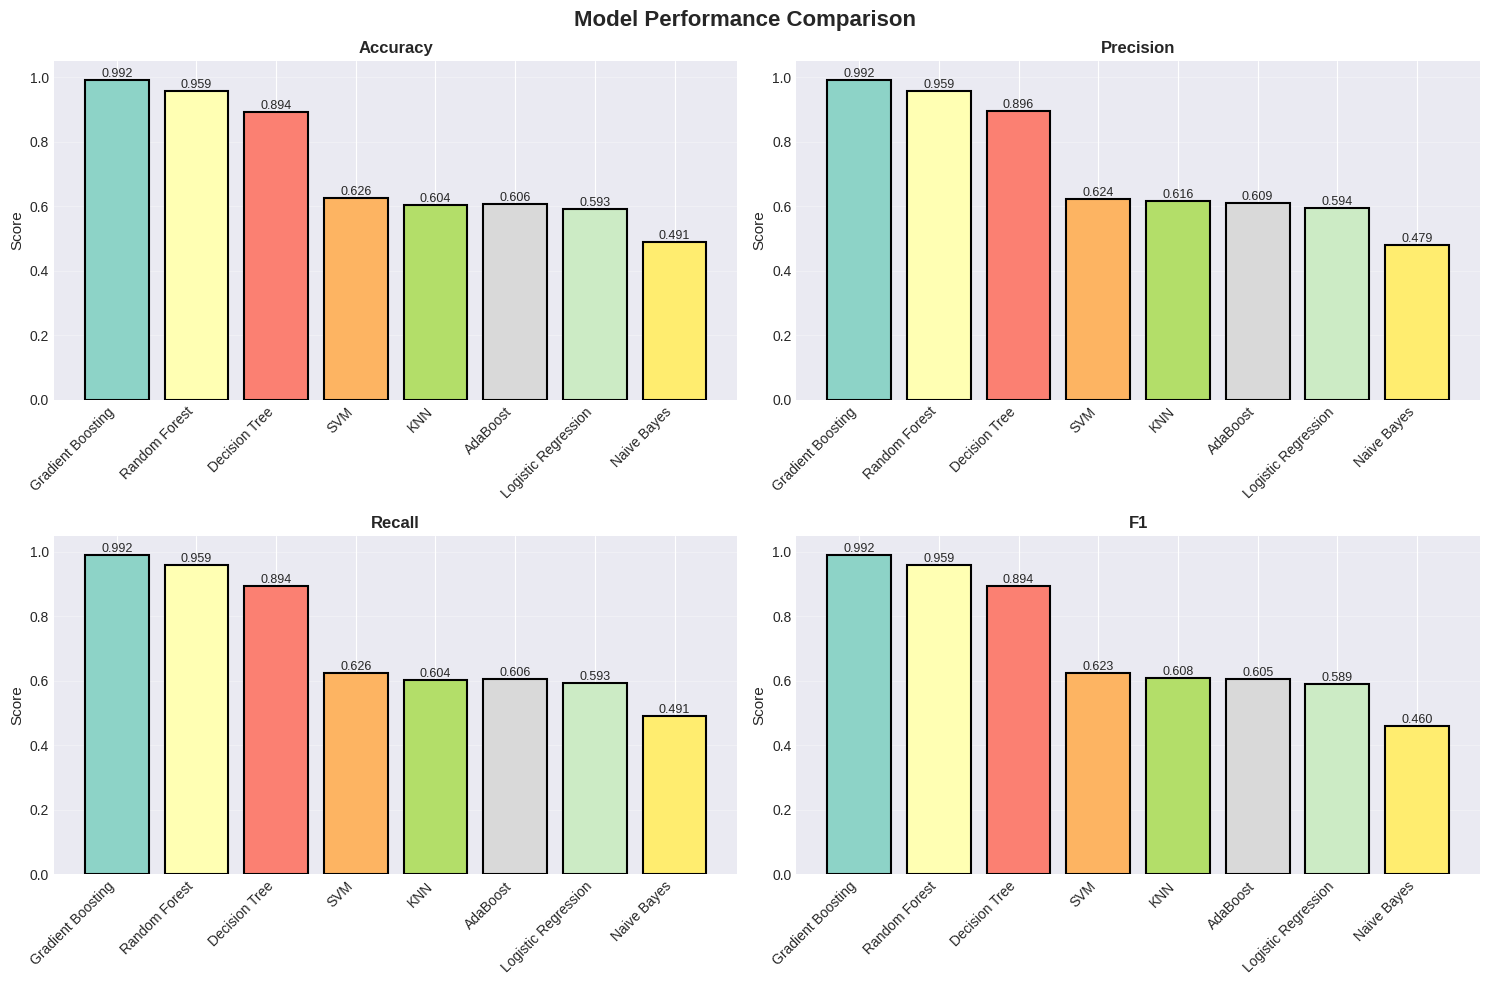

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Model Performance Comparison', fontsize=16, fontweight='bold')

metrics = ['accuracy', 'precision', 'recall', 'f1']
colors_models = plt.cm.Set3(np.linspace(0, 1, len(comparison_df)))

for idx, metric in enumerate(metrics):
    ax = axes[idx // 2, idx % 2]
    values = comparison_df[metric].values
    bars = ax.bar(range(len(comparison_df)), values, color=colors_models, edgecolor='black', linewidth=1.5)
    ax.set_xticks(range(len(comparison_df)))
    ax.set_xticklabels(comparison_df.index, rotation=45, ha='right')
    ax.set_title(f'{metric.capitalize()}', fontweight='bold')
    ax.set_ylabel('Score', fontsize=11)
    ax.set_ylim([0, 1.05])
    ax.grid(axis='y', alpha=0.3)

    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
best_model_name = comparison_df['f1'].idxmax()
best_model = models_dict[best_model_name]
best_predictions = results_dict[best_model_name]['predictions']

print("\n \n")
print(f"DETAILED EVALUATION - BEST MODEL: {best_model_name}")
print("\n \n")

print(f"\nClassification Report:\n")
print(classification_report(y_test, best_predictions,
                          target_names=label_encoder.classes_,
                          digits=4))

print(f"\nConfusion Matrix:")
cm = confusion_matrix(y_test, best_predictions)
print(cm)
print(f"\nConfusion Matrix (Decoded):")
cm_df = pd.DataFrame(cm, index=label_encoder.classes_, columns=label_encoder.classes_)
print(cm_df)


 

DETAILED EVALUATION - BEST MODEL: Gradient Boosting

 


Classification Report:

              precision    recall  f1-score   support

  AGGRESSIVE     0.9954    0.9776    0.9864       223
      NORMAL     0.9877    1.0000    0.9938       240
        SLOW     0.9925    0.9962    0.9944       266

    accuracy                         0.9918       729
   macro avg     0.9919    0.9913    0.9915       729
weighted avg     0.9918    0.9918    0.9917       729


Confusion Matrix:
[[218   3   2]
 [  0 240   0]
 [  1   0 265]]

Confusion Matrix (Decoded):
            AGGRESSIVE  NORMAL  SLOW
AGGRESSIVE         218       3     2
NORMAL               0     240     0
SLOW                 1       0   265


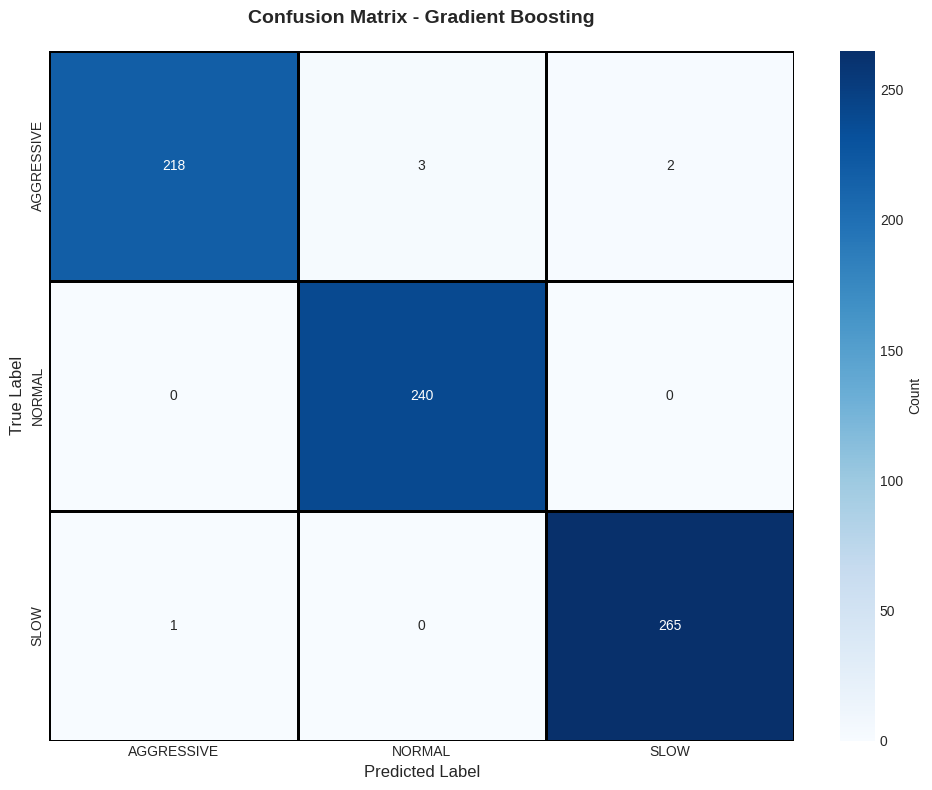

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_,
            cbar_kws={'label': 'Count'},
            linewidths=2, linecolor='black', ax=ax)
ax.set_title(f'Confusion Matrix - {best_model_name}', fontsize=14, fontweight='bold', pad=20)
ax.set_ylabel('True Label', fontsize=12)
ax.set_xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
print("\n \n")
print(f"CROSS-VALIDATION ANALYSIS - {best_model_name}")
print("\n \n")


kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(best_model, X_train_scaled, y_train, cv=kfold, scoring='f1_weighted')

print(f"\n5-Fold Cross-Validation F1-Scores:")
for i, score in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {score:.4f}")

print(f"\nMean CV Score: {cv_scores.mean():.4f}")
print(f"Std Dev: {cv_scores.std():.4f}")
print(f"Confidence Interval (95%): [{cv_scores.mean() - 1.96*cv_scores.std():.4f}, {cv_scores.mean() + 1.96*cv_scores.std():.4f}]")


 

CROSS-VALIDATION ANALYSIS - Gradient Boosting

 


5-Fold Cross-Validation F1-Scores:
  Fold 1: 0.9811
  Fold 2: 0.9777
  Fold 3: 0.9845
  Fold 4: 0.9949
  Fold 5: 0.9914

Mean CV Score: 0.9859
Std Dev: 0.0064
Confidence Interval (95%): [0.9735, 0.9984]



 

FEATURE IMPORTANCE - Gradient Boosting

Top 15 Most Important Features:
           Feature  Importance
  AccY_rolling_std    0.255418
 JerkY_rolling_max    0.156008
 JerkZ_rolling_max    0.132036
 JerkX_rolling_max    0.130890
  AccX_rolling_std    0.120834
 AccZ_rolling_mean    0.055665
  AccZ_rolling_std    0.042826
 AccY_rolling_mean    0.037653
 AccX_rolling_mean    0.033461
             GyroZ    0.006771
     GyroMagnitude    0.005395
              AccX    0.003184
JerkY_rolling_mean    0.002385
             GyroX    0.001914
JerkX_rolling_mean    0.001250


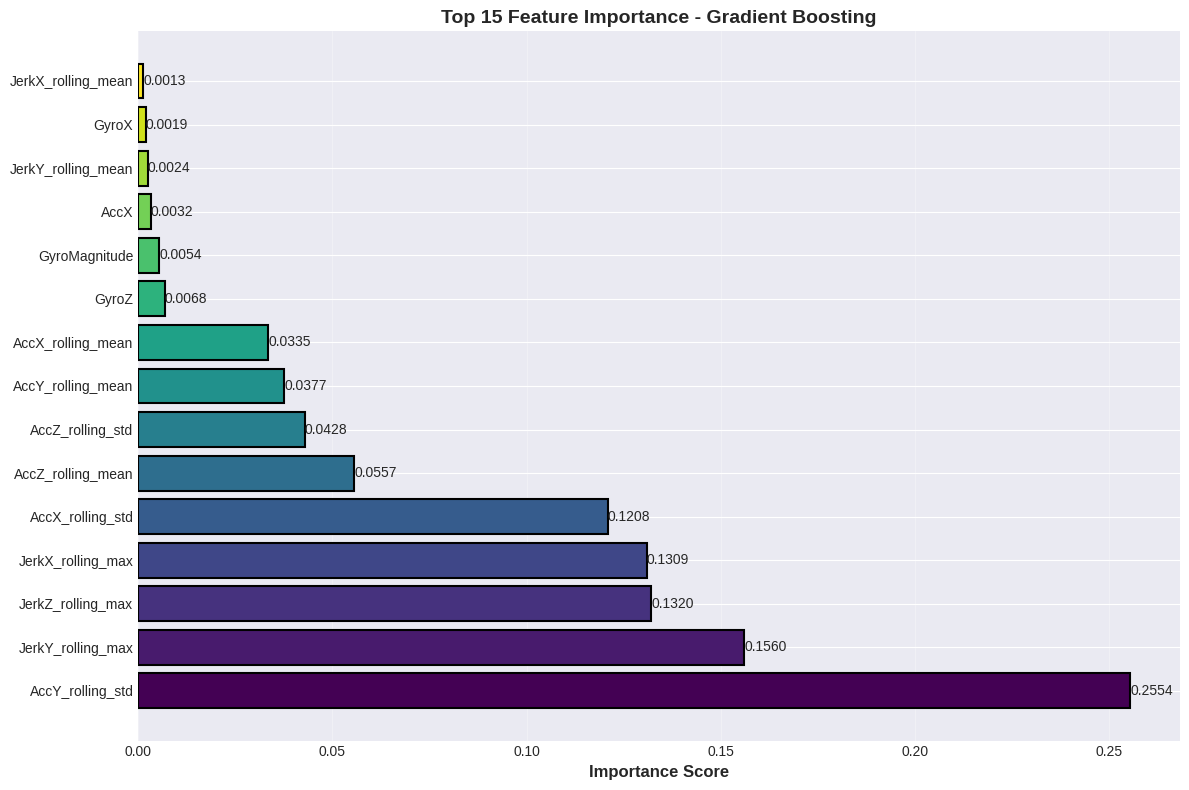

In [ ]:
if best_model_name in ['Random Forest', 'Gradient Boosting', 'Decision Tree', 'AdaBoost']:
    print("\n \n")
    print(f"FEATURE IMPORTANCE - {best_model_name}")


    feature_imp = pd.DataFrame({
        'Feature': feature_cols,
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)

    print(f"\nTop 15 Most Important Features:")
    print(feature_imp.head(15).to_string(index=False))

    fig, ax = plt.subplots(figsize=(12, 8))
    top_features = feature_imp.head(15)
    bars = ax.barh(range(len(top_features)), top_features['Importance'].values,
                    color=plt.cm.viridis(np.linspace(0, 1, len(top_features))),
                    edgecolor='black', linewidth=1.5)
    ax.set_yticks(range(len(top_features)))
    ax.set_yticklabels(top_features['Feature'].values)
    ax.set_xlabel('Importance Score', fontsize=12, fontweight='bold')
    ax.set_title(f'Top 15 Feature Importance - {best_model_name}', fontsize=14, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

    for i, bar in enumerate(bars):
        width = bar.get_width()
        ax.text(width, bar.get_y() + bar.get_height()/2.,
                f'{width:.4f}', ha='left', va='center', fontsize=10)

    plt.tight_layout()
    plt.show()

8. MODEL OPTIMIZATION & HYPERPARAMETER TUNING

In [ ]:
print("\n")
print(f"HYPERPARAMETER TUNING - {best_model_name}")
print("\n \n")


if best_model_name == 'Random Forest':
    print("\nTuning Random Forest hyperparameters...")
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [15, 20, 25],
        'min_samples_split': [3, 5],
        'min_samples_leaf': [1, 2]
    }

elif best_model_name == 'Gradient Boosting':
    print("\nTuning Gradient Boosting hyperparameters...")
    param_grid = {
        'n_estimators': [100, 150],
        'learning_rate': [0.05, 0.1, 0.15],
        'max_depth': [5, 7, 10]
    }

elif best_model_name == 'SVM':
    print("\nTuning SVM hyperparameters...")
    param_grid = {
        'C': [0.1, 1, 10],
        'gamma': ['scale', 'auto'],
        'kernel': ['rbf', 'poly']
    }
else:
    print("\nUsing default parameters (model not tuned)")
    param_grid = None

if param_grid:
    print(f"\nGrid Search Configuration:")
    print(f"Parameter combinations to test: {np.prod([len(v) for v in param_grid.values()])}")

    grid_search = GridSearchCV(best_model, param_grid, cv=3, scoring='f1_weighted', n_jobs=-1, verbose=1)
    grid_search.fit(X_train_scaled, y_train)

    print(f"\nBest Parameters: {grid_search.best_params_}")
    print(f"Best Cross-Validation Score: {grid_search.best_score_:.4f}")

    best_optimized_model = grid_search.best_estimator_
    y_pred_optimized = best_optimized_model.predict(X_test_scaled)
    optimized_accuracy = accuracy_score(y_test, y_pred_optimized)
    optimized_f1 = f1_score(y_test, y_pred_optimized, average='weighted')

    print(f"\nOptimized Model Test Performance:")
    print(f"  Accuracy: {optimized_accuracy:.4f}")
    print(f"  F1-Score: {optimized_f1:.4f}")

    original_accuracy = results_dict[best_model_name]['accuracy']
    original_f1 = results_dict[best_model_name]['f1']

    print(f"\nImprovement:")
    print(f"  Accuracy: {optimized_accuracy - original_accuracy:.4f}")
    print(f"  F1-Score: {optimized_f1 - original_f1:.4f}")

    best_model = best_optimized_model
    best_predictions = y_pred_optimized



HYPERPARAMETER TUNING - Gradient Boosting

 


Tuning Gradient Boosting hyperparameters...

Grid Search Configuration:
Parameter combinations to test: 18
Fitting 3 folds for each of 18 candidates, totalling 54 fits

Best Parameters: {'learning_rate': 0.15, 'max_depth': 7, 'n_estimators': 150}
Best Cross-Validation Score: 0.9876

Optimized Model Test Performance:
  Accuracy: 0.9959
  F1-Score: 0.9959

Improvement:
  Accuracy: 0.0041
  F1-Score: 0.0041


9. PREDICTION ON NEW DATA

In [ ]:
print("\n")
print("EXAMPLE: PREDICTION ON NEW DATA")
print("\n \n")


sample_indices = np.random.choice(len(X_test), 5, replace=False)
X_sample = X_test.iloc[sample_indices]
y_sample = y_test[sample_indices]

print("\nSample Data for Prediction:")
for idx, sample_idx in enumerate(sample_indices, 1):
    true_label = label_encoder.inverse_transform([y_sample[idx-1]])[0]
    print(f"\nSample {idx}:")
    print(f"  Feature Values (first 6): {X_sample.iloc[idx-1, :6].values}")
    print(f"  True Class: {true_label}")

    X_sample_scaled = scaler.transform(X_sample.iloc[[idx-1]])
    prediction = best_model.predict(X_sample_scaled)[0]
    probabilities = best_model.predict_proba(X_sample_scaled)[0]
    predicted_label = label_encoder.inverse_transform([prediction])[0]

    print(f"  Predicted Class: {predicted_label}")
    print(f"  Prediction Confidence:")
    for class_idx, class_name in enumerate(label_encoder.classes_):
        print(f"    - {class_name}: {probabilities[class_idx]:.4f}")

    match = "✓" if true_label == predicted_label else "✗"
    print(f"  Match: {match}")



EXAMPLE: PREDICTION ON NEW DATA

 


Sample Data for Prediction:

Sample 1:
  Feature Values (first 6): [-1.8096787  -1.4094648  -0.33883476  0.07528915  0.07330383  0.00297797]
  True Class: NORMAL
  Predicted Class: NORMAL
  Prediction Confidence:
    - AGGRESSIVE: 0.0000
    - NORMAL: 1.0000
    - SLOW: 0.0000
  Match: ✓

Sample 2:
  Feature Values (first 6): [ 0.5772822  -0.3661715  -1.2397652  -0.19593503  0.4361578   0.13553573]
  True Class: AGGRESSIVE
  Predicted Class: AGGRESSIVE
  Prediction Confidence:
    - AGGRESSIVE: 0.9997
    - NORMAL: 0.0000
    - SLOW: 0.0003
  Match: ✓

Sample 3:
  Feature Values (first 6): [-0.41870224  0.05317104  2.2214575   0.18402316 -0.00916298  0.13492486]
  True Class: NORMAL
  Predicted Class: NORMAL
  Prediction Confidence:
    - AGGRESSIVE: 0.0000
    - NORMAL: 0.9999
    - SLOW: 0.0001
  Match: ✓

Sample 4:
  Feature Values (first 6): [-0.12730014 -0.08631774  0.3479681  -0.01450805 -0.03420845  0.03474296]
  True Class: NORMAL
  Predic

Overfitting Check

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, f1_score

print("="*60)
print("OVERFITTING CHECK")
print("="*60)

y_train_pred = best_model.predict(X_train_scaled)

train_acc = accuracy_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred, average='weighted')

y_test_pred = best_model.predict(X_test_scaled)

test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average='weighted')

cv_scores = cross_val_score(best_model, X_train_scaled, y_train, cv=5, scoring='f1_weighted')

print(f"\n TRAIN PERFORMANCE")
print(f"Accuracy : {train_acc:.4f}")
print(f"F1 Score : {train_f1:.4f}")

print(f"\n TEST PERFORMANCE")
print(f"Accuracy : {test_acc:.4f}")
print(f"F1 Score : {test_f1:.4f}")

print(f"\n CROSS-VALIDATION (5-Fold)")
print(f"Scores   : {cv_scores}")
print(f"Mean F1  : {cv_scores.mean():.4f}")

print("\n ANALYSIS")
print("-"*40)

train_test_gap = train_f1 - test_f1
cv_test_gap = cv_scores.mean() - test_f1

print(f"Train - Test Gap : {train_test_gap:.4f}")
print(f"CV - Test Gap    : {cv_test_gap:.4f}")

if train_test_gap > 0.05:
    print(" Possible Overfitting (train >> test)")
elif test_f1 > train_f1:
    print(" Good Generalization (test >= train)")
else:
    print(" No significant overfitting detected")

OVERFITTING CHECK

 TRAIN PERFORMANCE
Accuracy : 1.0000
F1 Score : 1.0000

 TEST PERFORMANCE
Accuracy : 0.9959
F1 Score : 0.9959

 CROSS-VALIDATION (5-Fold)
Scores   : [0.9914304  0.99314674 0.99143219 0.9931407  0.99485033]
Mean F1  : 0.9928

 ANALYSIS
----------------------------------------
Train - Test Gap : 0.0041
CV - Test Gap    : -0.0031
 No significant overfitting detected
